In [1]:
import requests
import pandas as pd
import numpy as np
import ast
from pathlib import Path
import wfdb
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def clases_binarias(lista_superclases):
    """
    Atributo: lista_superclases --> es una lista que contiene o no, sin repetición, los 5 diagnósticos posibles:
    NORM, MI, STTC, CD, HYP. Este método devuelve un array con shape (5,) que tiene un 1.0 por cada clase presente
    y un 0.0 por cada clase ausente, en el orden en que las listamos.
    """
    clases = np.zeros(shape=5)
    if 'NORM' in lista_superclases:
        clases[0] = 1.0
    if 'MI' in lista_superclases:
        clases[1] = 1.0
    if 'STTC' in lista_superclases:
        clases[2] = 1.0
    if 'CD' in lista_superclases:
        clases[3] = 1.0
    if 'HYP' in lista_superclases:
        clases[4] = 1.0
    return clases

def array_targets(df_reindexado):
    """
    Atributo: df_reindexado --> la base de datos con todo el preprocesamiento hecho y la reindexación para tener índices de 0 a
    num_casos - 1. Devuelve una matriz con shape = (num_casos,5), donde la i-ésima fila es la asignación de clases binarias
    del electrocardiograma con índice i. Este método asume que los índices son los enteros consecutivos comenzando por 0.
    """
    matriz_binaria = np.empty(shape=(df_reindexado.shape[0],5))
    for i in range(df_reindexado.shape[0]):
        matriz_binaria[i,:] = clases_binarias(df_reindexado.loc[i,'superclasses'])
    return matriz_binaria

In [3]:
df_indexado = pd.read_csv("ptbxl_reduced.csv")
df_indexado=df_indexado.drop(['Unnamed: 0'],axis=1)
df_indexado['age'] = df_indexado['age']/100
#Normalizamos la edad para que esté entre 0 y 1, a fin de que no domine el cálculo final de la red neuronal

In [4]:
print(torch.__version__)
print(torch.cuda.is_available())

2.8.0+cpu
False


In [4]:
LOCAL_DIR = "C:/Users/Lenny/Desktop/Aprendizaje Automático/Portfolio manual/Diagnostico de arritmias/ptb-xl"  # Ajustar si la carpeta está en otro lugar

def ecg_to_tensor(filename_lr: str, local_dir: str = LOCAL_DIR) -> torch.Tensor:
    """
    Lee un registro ECG desde sus archivos .hea y .dat en Google Drive
    y lo devuelve como tensor PyTorch de shape (1000, 12).
    """
    path = str(Path(local_dir) / filename_lr)
    record = wfdb.rdrecord(path)
    return torch.tensor(record.p_signal, dtype=torch.float32)

In [9]:
matrix = ecg_to_tensor("records100/00000/00001_lr") #shape: (1000,12)

Esta matriz de shape (1000,12) registra las mediciones del electrocardiograma de un paciente. Cada columna corresponde a una "derivación", es decir a un electrodo ubicado en una posición determinada del cuerpo, y cada fila a un instante de tiempo. Como se mide latidos del corazón, esperamos ver un movimiento ondulatorio en cada columna. Graficamos el electrocardiograma para verificarlo.

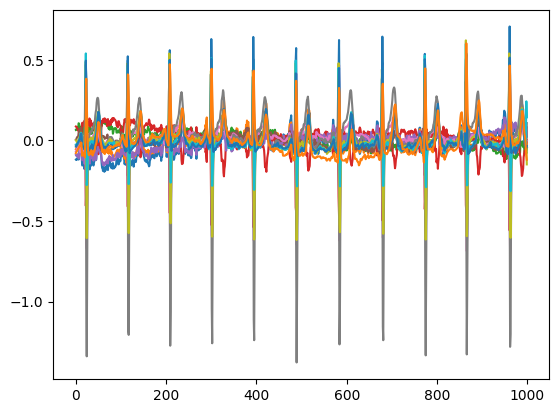

In [10]:
fig, ax = plt.subplots()
x = np.array([i for i in range(1000)])
for derivation in range(12):
    ax.plot(x,matrix[:,derivation])
plt.show()

Efectivamente, observamos un comportamiento ondulatorio en las 12 columnas, con picos de intensidad a intervalos regulares. Si este gráfico corresponde a un paciente normal, buscamos ahora uno con infarto de miocardio para hacernos una idea de qué diferencias pueden aparecer.

In [52]:
matrix_MI = ecg_to_tensor("records100/00000/00106_lr") #shape: (1000,12)
df_indexado.head(100) #vemos que el paciente de índice 95 tiene un MI como único diagnóstico. Lo usaremos como ejemplo.

,patient_id,sex,age,strat_fold,filename_lr,superclasses
0,15709.0,1,0.56,3,records100/00000/00001_lr,['NORM']
1,13243.0,0,0.19,2,records100/00000/00002_lr,['NORM']
2,20372.0,1,0.37,5,records100/00000/00003_lr,['NORM']
3,17014.0,0,0.24,3,records100/00000/00004_lr,['NORM']
4,17448.0,1,0.19,4,records100/00000/00005_lr,['NORM']
...,...,...,...,...,...,...
95,16066.0,0,0.38,5,records100/00000/00106_lr,['MI']
96,13453.0,1,0.58,5,records100/00000/00107_lr,['NORM']
97,11810.0,1,0.90,8,records100/00000/00108_lr,['NORM']
98,21312.0,1,0.18,2,records100/00000/00109_lr,['NORM']


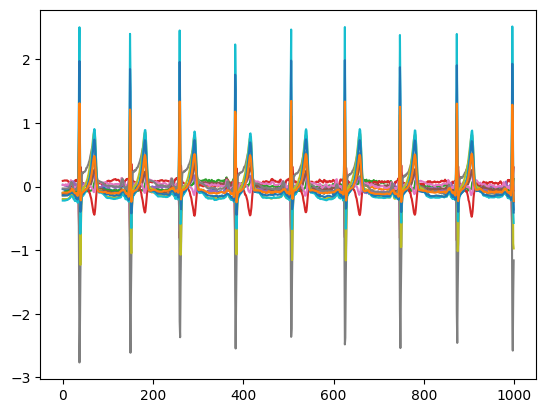

In [ ]:
fig, ax = plt.subplots()
x = np.array([i for i in range(1000)])
for derivation in range(12):
    ax.plot(x,matrix_MI[:,derivation])
plt.show()

Ahora veamos un ejemplo que sólo tiene CD:

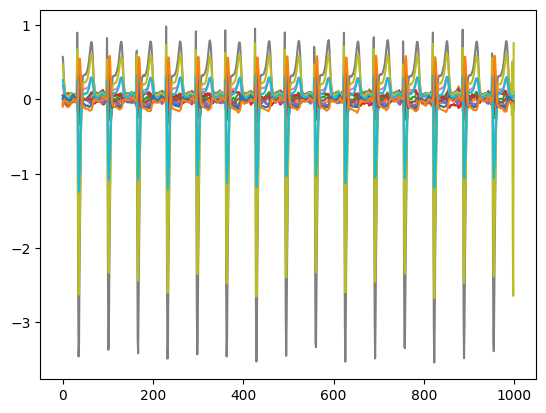

In [20]:
matrix_MI = ecg_to_tensor("records100/21000/21832_lr")
fig, ax = plt.subplots()
x = np.array([i for i in range(1000)])
for derivation in range(12):
    ax.plot(x,matrix_MI[:,derivation])
plt.show()

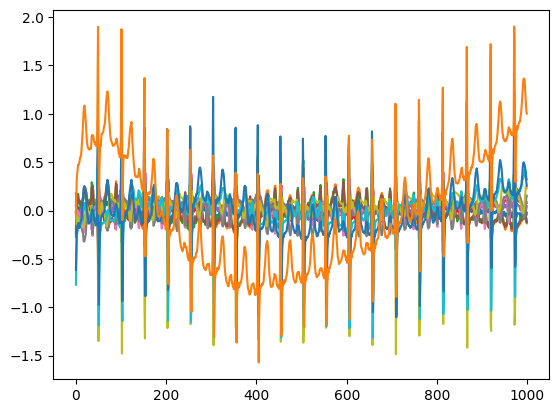

In [26]:
matrix_CD_HYP = ecg_to_tensor('records100/00000/00222_lr')
fig, ax = plt.subplots()
x = np.array([i for i in range(1000)])
for derivation in range(12):
    ax.plot(x,matrix_CD_HYP[:,derivation])
plt.show()

In [24]:
for i in range(200):
    print(df_indexado.loc[i])

Unnamed: 0                              0
patient_id                        15709.0
sex                                     1
age                                  56.0
strat_fold                              3
filename_lr     records100/00000/00001_lr
superclasses                     ['NORM']
Name: 0, dtype: object
Unnamed: 0                              1
patient_id                        13243.0
sex                                     0
age                                  19.0
strat_fold                              2
filename_lr     records100/00000/00002_lr
superclasses                     ['NORM']
Name: 1, dtype: object
Unnamed: 0                              2
patient_id                        20372.0
sex                                     1
age                                  37.0
strat_fold                              5
filename_lr     records100/00000/00003_lr
superclasses                     ['NORM']
Name: 2, dtype: object
Unnamed: 0                              3
patient

En el MI y el CD vemos ondas de mayor amplitud que en el caso normal (aumenta la escala del eje vertical). Además, el período de las ondulaciones en el MI es más extenso puesto que observamos menos picos. Suponemos que el diagnóstico se deduce del periodo y la amplitud de las diferentes ondulaciones, y nos proponemos diseñar una red neuronal que capture estos patrones y aproveche el comportamiento periódico.

In [10]:
device = "cuda" if torch.cuda.is_available() else "cpu"

from torch.utils.data import Dataset, DataLoader, random_split

"""
versión que accede los items leyéndolos del disco
class ECG(Dataset):
    def __init__(self,df_metadata):
        self.metadata = df_metadata
        targets = array_targets(df_metadata)
        self.y = torch.from_numpy(targets).type(torch.float32).to(device)

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self,idx):
        demo = torch.tensor([self.metadata.loc[idx,'sex'],self.metadata.loc[idx,'age']],dtype=torch.float32,device=device)
        ecg = ecg_to_tensor(self.metadata.loc[idx,'filename_lr']).to(device)
        return demo, ecg, self.y[idx]
"""
class ECG(Dataset):
    def __init__(self, df_metadata):
        self.metadata = df_metadata
        n = len(df_metadata)

        # Targets (igual que antes)
        targets = array_targets(df_metadata)
        self.y = torch.from_numpy(targets).type(torch.float32).to(device)

        # Datos demográficos de todas las instancias: (N, 2)
        self.demo = torch.tensor(
            df_metadata[['sex', 'age']].values, dtype=torch.float32
        ).to(device)

        # Todos los ECG en un solo tensor: (N, 1000, 12)
        self.ecg = torch.empty((n, 1000, 12), dtype=torch.float32)
        for i in range(n):
            self.ecg[i] = ecg_to_tensor(df_metadata.loc[i, 'filename_lr'])
            if (i + 1) % 1000 == 0:
                print(f"Cargados {i + 1}/{n} registros")
        self.ecg = self.ecg.to(device)

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, idx):
        return self.demo[idx], self.ecg[idx], self.y[idx]


In [11]:
"""
Acá aplicamos la división recomendada del dataset, donde el fold 9 es el de validación, el 10 es el de test
y el resto para entrenamiento.
"""
registros_corruptos = ['records100/08000/08296_lr', 'records100/08000/08297_lr'] #los detectados con el código de diagnóstico de Claude
df_indexado = df_indexado[~df_indexado['filename_lr'].isin(registros_corruptos)].reset_index(drop=True)
train_dataset = ECG(df_indexado[df_indexado['strat_fold'] < 9].reset_index())
validation_dataset = ECG(df_indexado[df_indexado['strat_fold'] == 9].reset_index())
test_dataset = ECG(df_indexado[df_indexado['strat_fold'] == 10].reset_index())

Cargados 1000/14765 registros
Cargados 2000/14765 registros
Cargados 3000/14765 registros
Cargados 4000/14765 registros
Cargados 5000/14765 registros
Cargados 6000/14765 registros
Cargados 7000/14765 registros
Cargados 8000/14765 registros
Cargados 9000/14765 registros
Cargados 10000/14765 registros
Cargados 11000/14765 registros
Cargados 12000/14765 registros
Cargados 13000/14765 registros
Cargados 14000/14765 registros
Cargados 1000/1843 registros
Cargados 1000/1851 registros


In [12]:
batch_size = 32

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    dataset=validation_dataset,
    batch_size=batch_size,
    shuffle=False, 
    num_workers=0
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

In [14]:
#Como el loop de entrenamiento no pudo comenzar, con ayuda de Claude diagnosticamos que hay fallas de origen en los datos
#de los electrocardiogramas. El LLM nos da este código para detectar las fallas específicas, que son 2.

for idx in range(len(train_dataset.metadata)):
    filename = train_dataset.metadata.loc[idx, 'filename_lr']
    try:
        ecg_to_tensor(filename)
    except Exception as e:
        print(f"Falla en idx={idx}, archivo={filename}: {e}")

KeyboardInterrupt: 

In [15]:
ejemplo = torch.tensor([[1,2,3],[4,5,6],[7,8,9],[10,11,12]]) #shape: (4,3)
transp = ejemplo.transpose(0,1) #shape: (3,4)
transp[:,0:2]

tensor([[1, 4],
        [2, 5],
        [3, 6]])

Ya cargamos nuestros datos. Ahora debemos diseñar la arquitectura, para lo cual desarrollamos primero los conceptos esenciales que nos llevan al diseño elegido. Como creemos que el diagnóstico depende de los comportamientos de las 12 derivaciones y de las interrelaciones entre ellas, y que todos son ondulatorios, queremos poder capturar los diferentes picos, y además distinguir si son positivos o negativos. Queremos captar las características de franjas sucesivas de tiempo, además de conectar las franjas de tiempo consecutivas, para obtener los patrones propios de cada etapa y saber qué patrones vienen después de otros. Por eso vamos a dividir los 1000 instantes en 20 etapas de 50 instantes consecutivos cada una, para estudiar los patrones de cada etapa. Para conectar etapas consecutivas, vamos a dividir a las 20 en 5 y luego unir los 4 períodos de cada una de esas 5 etapas en una única tira de valores. Dado que los instantes de tiempo y las etapas son esencialmente iguales, en cada unión se usará los mismos parámetros (y luego cambian para la siguiente unión de etapas).

Además, habrá parámetros para la parte positiva y otros para la negativa que a su vez se dividirán en dos tipos: uno realizará productos con una matriz fila para conseguir comportamientos de etapa de cada variación individual y conservarlos separados a lo largo del proceso. La otra mitad consistirá en realizar productos matriciales de matriz completa para crear conexión total entre las 12 derivaciones, a fin de observar las interrelaciones necesarias entre derivaciones para los diferentes diagnósticos.

En una primera prueba, usamos los mismos parámetros para las diferentes etapas y también para las diferentes derivaciones. En una segunda prueba, observando los resultados, usamos un conjunto de parámetros distinto para cada una de las 12 derivaciones, conservando la invariancia temporal de los mismos.

Interpretamos que los instantes de tiempo no tienen propiedades diferentes entre sí; que un pico aparezca antes o después depende del instante en que se comenzó a medir los latidos del corazón y no de la presencia o ausencia de patologías. Por eso, 

In [29]:
#MODELO NUEVO
from torch import nn
import torch.nn.functional as F
class ECG_model(nn.Module):
    def __init__(self):
        super().__init__()
        self.W_plus = nn.Parameter(torch.randn((1,50), dtype=torch.float32), requires_grad=True)
        self.W_minus = nn.Parameter(torch.randn((1,50), dtype=torch.float32), requires_grad=True)
        self.Q_plus = nn.Parameter(torch.randn((12,12), dtype=torch.float32), requires_grad=True)
        self.Q_minus = nn.Parameter(torch.randn((12,12), dtype=torch.float32), requires_grad=True)
        self.T_plus = nn.Parameter(torch.randn((1,4), dtype=torch.float32), requires_grad=True)
        self.T_minus = nn.Parameter(torch.randn((1,4), dtype=torch.float32), requires_grad=True)
        self.P_plus = nn.Parameter(torch.randn((1,4), dtype=torch.float32), requires_grad=True)
        self.P_minus = nn.Parameter(torch.randn((1,4), dtype=torch.float32), requires_grad=True)
        self.S_plus = nn.Parameter(torch.randn((1,5), dtype=torch.float32), requires_grad=True)
        self.S_minus = nn.Parameter(torch.randn((1,5), dtype=torch.float32), requires_grad=True)
        self.Z_plus = nn.Parameter(torch.randn((1,5), dtype=torch.float32), requires_grad=True)
        self.Z_minus = nn.Parameter(torch.randn((1,5), dtype=torch.float32), requires_grad=True)
        self.m_age = nn.Parameter(torch.randn((1),dtype=torch.float32), requires_grad=True)
        self.b_age = nn.Parameter(torch.randn((1),dtype=torch.float32), requires_grad=True)
        self.m_sex = nn.Parameter(torch.randn((1),dtype=torch.float32), requires_grad=True)
        self.b_sex = nn.Parameter(torch.randn((1),dtype=torch.float32), requires_grad=True)
        self.R = nn.Parameter(torch.randn((50,5), dtype=torch.float32), requires_grad=True)
        self.final_bias = nn.Parameter(torch.randn((1,5), dtype=torch.float32), requires_grad=True)

    """
    def forward_loop(self, demo, ecg):
        #Las batch_size instancias llegan apiladas con stack(dim=0)
        #el ecg tiene shape (B,1000,12)
        B = ecg.shape[0]  # tamaño del batch
        M1_plus = F.relu(ecg)
        M1_minus = F.relu(-ecg)
        resultados_instancias = []
        for instance in range(B):
            lista_M2_plus = []
            lista_M2_minus = []
            for i in range(20):
                lista_M2_plus.append((torch.matmul(self.W_plus,M1_plus[instance,i*50:(i+1)*50,:]).squeeze()))
                lista_M2_minus.append((torch.matmul(self.W_minus,M1_minus[instance,i*50:(i+1)*50,:]).squeeze()))
            M2_plus = torch.stack(lista_M2_plus,dim=0) #shape: (20,12)
            M2_minus = torch.stack(lista_M2_minus,dim=0)
            N2_plus = F.relu(torch.matmul(M2_plus,self.Q_plus)) #shape: (20,12)
            N2_minus = F.relu(torch.matmul(M2_minus,self.Q_minus))
            M2_plus = F.relu(M2_plus)
            M2_minus = F.relu(M2_minus)
            lista_M3_plus = []
            lista_M3_minus = []
            lista_N3_plus = []
            lista_N3_minus = []
            for j in range(5):
                lista_M3_plus.append((torch.matmul(self.T_plus,M2_plus[4*j:4*(j+1),:])).squeeze())
                lista_M3_minus.append((torch.matmul(self.T_minus,M2_minus[4*j:4*(j+1),:])).squeeze())
                lista_N3_plus.append((torch.matmul(self.P_plus,N2_plus[4*j:4*(j+1),:])).squeeze())
                lista_N3_minus.append((torch.matmul(self.P_minus,N2_minus[4*j:4*(j+1),:])).squeeze())
            M3_plus = F.relu(torch.stack(lista_M3_plus,dim=0)) #shape: (5,12)
            M3_minus = F.relu(torch.stack(lista_M3_minus,dim=0))
            N3_plus = F.relu(torch.stack(lista_N3_plus,dim=0)) #shape: (5,12)
            N3_minus = F.relu(torch.stack(lista_N3_minus,dim=0))
            M4_plus = F.relu(torch.matmul(self.S_plus,M3_plus))
            M4_minus = F.relu(torch.matmul(self.S_minus,M3_minus))
            N4_plus = F.relu(torch.matmul(self.Z_plus,N3_plus)) #shape: (1,12)
            N4_minus = F.relu(torch.matmul(self.Z_minus,N3_minus))
            cadena_instancia = torch.zeros(size=(1,50), device=ecg.device, dtype=ecg.dtype).to(device)
            #hay que moverlo porque los tensores nuevos se crean en CPU por defecto
            cadena_instancia[0,0:12] = M4_plus[0,:]
            cadena_instancia[0,12:24] = M4_minus[0,:]
            cadena_instancia[0,24:36] = N4_plus[0,:]
            cadena_instancia[0,36:48] = N4_minus[0,:]
            cadena_instancia[0,48] = demo[instance, 0] * self.m_sex + self.b_sex
            cadena_instancia[0,49] = demo[instance, 1] * self.m_age + self.b_age
            resultado_final_instancia = (torch.matmul(cadena_instancia,self.R) + self.final_bias).squeeze()
            resultados_instancias.append(F.sigmoid(resultado_final_instancia))
        return torch.stack(resultados_instancias,dim=0)
    """
    
    def forward(self, demo, ecg):
    # demo: (B,2)   ecg: (B,1000,12)
        B = ecg.shape[0]

        M1_plus = F.relu(ecg)    # (B,1000,12)
        M1_minus = F.relu(-ecg)

    # Bloques de 50 instantes: (B,1000,12) -> (B,20,50,12)
    # Equivale a W_plus @ M1_plus[instance, 50i:50(i+1), :] para cada i
        M2_plus = torch.einsum('k,bikj->bij', self.W_plus[0], M1_plus.reshape(B, 20, 50, 12))     # (B,20,12)
        M2_minus = torch.einsum('k,bikj->bij', self.W_minus[0], M1_minus.reshape(B, 20, 50, 12))

    # N2 usa M2 antes de la ReLU, igual que en tu versión
        N2_plus = F.relu(torch.matmul(M2_plus, self.Q_plus))     # (B,20,12)
        N2_minus = F.relu(torch.matmul(M2_minus, self.Q_minus))
        M2_plus = F.relu(M2_plus)
        M2_minus = F.relu(M2_minus)

    # Bloques de 4 etapas: (B,20,12) -> (B,5,4,12)
    # Equivale a T_plus @ M2_plus[4j:4(j+1), :] para cada j
        M3_plus = F.relu(torch.einsum('k,bjkc->bjc', self.T_plus[0], M2_plus.reshape(B, 5, 4, 12)))    # (B,5,12)
        M3_minus = F.relu(torch.einsum('k,bjkc->bjc', self.T_minus[0], M2_minus.reshape(B, 5, 4, 12)))
        N3_plus = F.relu(torch.einsum('k,bjkc->bjc', self.P_plus[0], N2_plus.reshape(B, 5, 4, 12)))
        N3_minus = F.relu(torch.einsum('k,bjkc->bjc', self.P_minus[0], N2_minus.reshape(B, 5, 4, 12)))

    # (1,5) @ (B,5,12) -> (B,1,12)
        M4_plus = F.relu(torch.matmul(self.S_plus, M3_plus))
        M4_minus = F.relu(torch.matmul(self.S_minus, M3_minus))
        N4_plus = F.relu(torch.matmul(self.Z_plus, N3_plus))
        N4_minus = F.relu(torch.matmul(self.Z_minus, N3_minus))

        cadena = torch.cat([
            M4_plus.squeeze(1),                       # (B,12) -> posiciones 0:12
            M4_minus.squeeze(1),                      # 12:24
            N4_plus.squeeze(1),                       # 24:36
            N4_minus.squeeze(1),                      # 36:48
            demo[:, 0:1] * self.m_sex + self.b_sex,   # (B,1)  -> 48
            demo[:, 1:2] * self.m_age + self.b_age,   # (B,1)  -> 49
        ], dim=1)                                     # (B,50)

        return torch.matmul(cadena, self.R) + self.final_bias   # (B,5)

In [33]:
#Nuevo modelo con un canal para cada derivación
from torch import nn
import torch.nn.functional as F

class ECG_model(nn.Module):
    def __init__(self):
        super().__init__()
        # Una fila por derivación (12), compartida entre bloques temporales
        self.W_plus = nn.Parameter(torch.randn((12,50), dtype=torch.float32), requires_grad=True)
        self.W_minus = nn.Parameter(torch.randn((12,50), dtype=torch.float32), requires_grad=True)
        # Q mezcla derivaciones: sin cambios
        self.Q_plus = nn.Parameter(torch.randn((12,12), dtype=torch.float32), requires_grad=True)
        self.Q_minus = nn.Parameter(torch.randn((12,12), dtype=torch.float32), requires_grad=True)
        self.T_plus = nn.Parameter(torch.randn((12,4), dtype=torch.float32), requires_grad=True)
        self.T_minus = nn.Parameter(torch.randn((12,4), dtype=torch.float32), requires_grad=True)
        self.P_plus = nn.Parameter(torch.randn((12,4), dtype=torch.float32), requires_grad=True)
        self.P_minus = nn.Parameter(torch.randn((12,4), dtype=torch.float32), requires_grad=True)
        self.S_plus = nn.Parameter(torch.randn((12,5), dtype=torch.float32), requires_grad=True)
        self.S_minus = nn.Parameter(torch.randn((12,5), dtype=torch.float32), requires_grad=True)
        self.Z_plus = nn.Parameter(torch.randn((12,5), dtype=torch.float32), requires_grad=True)
        self.Z_minus = nn.Parameter(torch.randn((12,5), dtype=torch.float32), requires_grad=True)
        self.m_age = nn.Parameter(torch.randn((1), dtype=torch.float32), requires_grad=True)
        self.b_age = nn.Parameter(torch.randn((1), dtype=torch.float32), requires_grad=True)
        self.m_sex = nn.Parameter(torch.randn((1), dtype=torch.float32), requires_grad=True)
        self.b_sex = nn.Parameter(torch.randn((1), dtype=torch.float32), requires_grad=True)
        self.R = nn.Parameter(torch.randn((50,5), dtype=torch.float32), requires_grad=True)
        self.final_bias = nn.Parameter(torch.randn((1,5), dtype=torch.float32), requires_grad=True)

    def forward(self, demo, ecg):
        # demo: (B,2)   ecg: (B,1000,12)
        B = ecg.shape[0]

        M1_plus = F.relu(ecg)    # (B,1000,12)
        M1_minus = F.relu(-ecg)

        # Bloques de 50 instantes: (B,1000,12) -> (B,20,50,12)
        # M2[b,i,j] = sum_k W[j,k] * M1[b,i,k,j]  (fila j de W para la derivación j)
        M2_plus = torch.einsum('jk,bikj->bij', self.W_plus, M1_plus.reshape(B, 20, 50, 12))     # (B,20,12)
        M2_minus = torch.einsum('jk,bikj->bij', self.W_minus, M1_minus.reshape(B, 20, 50, 12))

        # N2 usa M2 antes de la ReLU
        N2_plus = F.relu(torch.matmul(M2_plus, self.Q_plus))     # (B,20,12)
        N2_minus = F.relu(torch.matmul(M2_minus, self.Q_minus))
        M2_plus = F.relu(M2_plus)
        M2_minus = F.relu(M2_minus)

        # Bloques de 4 etapas: (B,20,12) -> (B,5,4,12)
        # M3[b,j,c] = sum_k T[c,k] * M2[b,j,k,c]
        M3_plus = F.relu(torch.einsum('ck,bjkc->bjc', self.T_plus, M2_plus.reshape(B, 5, 4, 12)))    # (B,5,12)
        M3_minus = F.relu(torch.einsum('ck,bjkc->bjc', self.T_minus, M2_minus.reshape(B, 5, 4, 12)))
        N3_plus = F.relu(torch.einsum('ck,bjkc->bjc', self.P_plus, N2_plus.reshape(B, 5, 4, 12)))
        N3_minus = F.relu(torch.einsum('ck,bjkc->bjc', self.P_minus, N2_minus.reshape(B, 5, 4, 12)))

        # M4[b,c] = sum_j S[c,j] * M3[b,j,c]
        M4_plus = F.relu(torch.einsum('cj,bjc->bc', self.S_plus, M3_plus))     # (B,12)
        M4_minus = F.relu(torch.einsum('cj,bjc->bc', self.S_minus, M3_minus))
        N4_plus = F.relu(torch.einsum('cj,bjc->bc', self.Z_plus, N3_plus))
        N4_minus = F.relu(torch.einsum('cj,bjc->bc', self.Z_minus, N3_minus))

        cadena = torch.cat([
            M4_plus,                                  # (B,12) -> posiciones 0:12
            M4_minus,                                 # 12:24
            N4_plus,                                  # 24:36
            N4_minus,                                 # 36:48
            demo[:, 0:1] * self.m_sex + self.b_sex,   # (B,1)  -> 48
            demo[:, 1:2] * self.m_age + self.b_age,   # (B,1)  -> 49
        ], dim=1)                                     # (B,50)

        return torch.matmul(cadena, self.R) + self.final_bias   # (B,5)
    #evitamos calcular la sigmoide al final para luego usar bcewithlogits, que es numéricamente más estable

In [ ]:
#Comprobamos que la versión original y la comprimida de Claude sean equivalentes:
model_0 = ECG_model()
model_0 = model_0.to(device)
demo, ecg, y = next(iter(test_loader))
with torch.inference_mode():
    print(torch.allclose(model_0.forward_loop(demo, ecg), model_0(demo, ecg), atol=1e-5))  # da True

True


In [22]:
W_prueba = torch.randn((1,50), dtype=torch.float32)
ecg_prueba = torch.randn((1000,12), dtype=torch.float32)
mult = torch.matmul(W_prueba,ecg_prueba[0:50,:]).squeeze()
mult2 = torch.matmul(W_prueba,ecg_prueba[50:100,:]).squeeze()
torch.stack([mult,mult2],dim=0).shape

torch.Size([2, 12])

In [43]:
torch.randn((1),dtype=torch.float32).shape

torch.Size([1])

In [9]:
torch.manual_seed(42)
loss = nn.BCELoss(reduction='mean')
model_0 = ECG_model()
model_0 = model_0.to(device) #Para mover el modelo y todos sus parámetros al device que tengamos
predictions = []
with torch.inference_mode():  # o torch.no_grad() (porque si queremos sólo predecir no hace falta calcular gradientes)
    for demo, ecg, y in test_loader: #deducción: test_loader es una lista de batches; donde cada elemento es una tupla de batches
    #por cada "sección" de la instancia (en este caso el feature X y el target y), que son los atributos de la clase
    #que heredó de Dataset.
        batch_preds = model_0(demo,ecg) #model_0 era el nombre del modelo que creamos y estamos entrenando. Es decir,
        #llamar a model_0 como "función" realiza una pasada forward y devuelve las predicciones para las instancias dadas como parámetro.
        predictions.append(batch_preds)
        #print(loss(batch_preds,y))

    y_preds = torch.cat(predictions)

In [45]:
model_1 = ECG_model()
model_1 = model_1.to(device)
frac_pos = train_dataset.y.mean(dim=0)          # proporción de positivos por clase
pos_weights = (1 - frac_pos)/frac_pos         # cantidad de negativos por cada positivo
#loss = nn.BCELoss(reduction='mean') si usamos esta hay que aplicar la sigmoide en el forward
loss = nn.BCEWithLogitsLoss(
    weight=torch.tensor([1.0, 10.0, 5.0, 5.0, 2.0],device=device), pos_weight=pos_weights    # = class_weights                               # = pos_weight
)
#optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)
optimizer = torch.optim.Adam(model_1.parameters(), lr=1e-3)
torch.manual_seed(42)

epochs = 50

# Empty lists to track values
train_loss_values = []
validation_loss_values = []
epoch_count = []

for epoch in range(epochs):
    ### Training
    model_1.train() #dispone el modelo a ser entrenado
    train_loss = 0

    # Loop through training batches
    for demo_batch, ecg_batch, y_batch in train_loader:
        # 1. Forward pass
        y_pred = model_1(demo_batch,ecg_batch)

        # 2. Calculate loss
        loss_value = loss(y_pred, y_batch)

        # 3. Zero gradients
        optimizer.zero_grad()

        # 4. Backpropagation
        loss_value.backward()

        # 5. Update parameters
        optimizer.step()

        # Accumulate batch loss
        train_loss += loss_value.item()

    # Calculate average training loss for the epoch
    train_loss = train_loss / len(train_loader)

    ### Testing
    model_1.eval() #análogo a model.train(): dispone el modelo a ser evaluado
    validation_loss = 0

    with torch.inference_mode(): #no calcula train Loss ni gradientes
        # Loop through test batches
        for demo_batch, ecg_batch, y_batch in validation_loader:
            # 1. Forward pass on test data
            validation_pred = model_1(demo_batch,ecg_batch)

            # 2. Calculate test loss
            batch_validation_loss = loss(validation_pred, y_batch)

            # Accumulate batch test loss
            validation_loss += batch_validation_loss.item()

        # Calculate average test loss for the epoch
        validation_loss = validation_loss / len(validation_loader)

    # Print progress for every epoch
    epoch_count.append(epoch)
    train_loss_values.append(train_loss)
    validation_loss_values.append(validation_loss)
    print(f"Epoch: {epoch} | Train Loss: {train_loss:.5f} | Test Loss: {validation_loss:.5f}")

Epoch: 0 | Train Loss: 30.64987 | Test Loss: 15.66822
Epoch: 1 | Train Loss: 11.84114 | Test Loss: 8.80945
Epoch: 2 | Train Loss: 7.55479 | Test Loss: 6.46169
Epoch: 3 | Train Loss: 5.94935 | Test Loss: 5.47792
Epoch: 4 | Train Loss: 5.24278 | Test Loss: 5.01749
Epoch: 5 | Train Loss: 4.87827 | Test Loss: 4.76868
Epoch: 6 | Train Loss: 4.67315 | Test Loss: 4.61785
Epoch: 7 | Train Loss: 4.54399 | Test Loss: 4.51202
Epoch: 8 | Train Loss: 4.45414 | Test Loss: 4.43500
Epoch: 9 | Train Loss: 4.38228 | Test Loss: 4.37513
Epoch: 10 | Train Loss: 4.32413 | Test Loss: 4.32287
Epoch: 11 | Train Loss: 4.26967 | Test Loss: 4.27545
Epoch: 12 | Train Loss: 4.21974 | Test Loss: 4.23148
Epoch: 13 | Train Loss: 4.17719 | Test Loss: 4.19741
Epoch: 14 | Train Loss: 4.13869 | Test Loss: 4.15916
Epoch: 15 | Train Loss: 4.09929 | Test Loss: 4.12066
Epoch: 16 | Train Loss: 4.06321 | Test Loss: 4.09607
Epoch: 17 | Train Loss: 4.02339 | Test Loss: 4.06166
Epoch: 18 | Train Loss: 3.98535 | Test Loss: 4.04035


In [ ]:
from sklearn.metrics import roc_auc_score

model_1.eval()
preds = []
with torch.inference_mode():
    for demo, ecg, y in validation_loader:
        preds.append(model_1(demo, ecg))
preds = torch.cat(preds).cpu().numpy()
y_val = validation_dataset.y.cpu().numpy()

for i, clase in enumerate(['NORM', 'MI', 'STTC', 'CD', 'HYP']):
    print(clase, roc_auc_score(y_val[:, i], preds[:, i]))

"""
Resultados para la primera arquitectura (mismos parámetros para cada etapa y derivación) y optimizador SGD
NORM 0.3893214899227327
MI 0.6365552952569966
STTC 0.7114649039430858
CD 0.4174954290681294
HYP 0.33809954699628947

Resultados para la misma arquitectura pero con optimizador Adam
NORM 0.7867055006114931
MI 0.7504901910636891
STTC 0.5742273682997783
CD 0.736550969637023
HYP 0.7653315577409001

Resultados para una nueva versión donde hay un canal por cada derivación
NORM 0.8097183832071465
MI 0.7351706546906597
STTC 0.7000086408018664
CD 0.7767227167820638
HYP 0.7001838193448519

Ahora probamos este último modelo con 50 epochs, ya que en los primeros 10 no se observó un estancamiento
en las pérdidas de entrenamiento y validación
NORM 0.9069764427823768
MI 0.7935093588130385
STTC 0.8201244275468763
CD 0.8193552738063123
HYP 0.8111754194268025

Prueba con 100 epochs
NORM 0.9116392260545609
MI 0.8169788544362718
STTC 0.8530458826579108
CD 0.8231139286035429
HYP 0.83079799221471

Prueba con 100 epochs y Loss ponderada por clase
NORM 0.9010924403411166
MI 0.8414185021125105
STTC 0.8421267893660533
CD 0.8117225669154453
HYP 0.8290935372988232

Prueba con 50 epochs y modelo viejo (mismos parámetros para todas las derivaciones)
NORM 0.8662114046435783
MI 0.8159541419866122
STTC 0.7888792879979263
CD 0.790736744297575
HYP 0.7918743882173507

Prueba del modelo nuevo con 50 epochs y agregando pesos para las clases y los positivos
NORM 0.8927282967026493
MI 0.7991120295444547
STTC 0.8329617788530775
CD 0.8132751850852741
HYP 0.8106120102893306
"""

NORM 0.8927282967026493
MI 0.7991120295444547
STTC 0.8329617788530775
CD 0.8132751850852741
HYP 0.8106120102893306


'\nResultados para la primera arquitectura (mismos parámetros para cada etapa y derivación) y optimizador SGD\nNORM 0.3893214899227327\nMI 0.6365552952569966\nSTTC 0.7114649039430858\nCD 0.4174954290681294\nHYP 0.33809954699628947\n\nResultados para la misma arquitectura pero con optimizador Adam\nNORM 0.7867055006114931\nMI 0.7504901910636891\nSTTC 0.5742273682997783\nCD 0.736550969637023\nHYP 0.7653315577409001\n\nResultados para una nueva versión donde hay un canal por cada derivación\nNORM 0.8097183832071465\nMI 0.7351706546906597\nSTTC 0.7000086408018664\nCD 0.7767227167820638\nHYP 0.7001838193448519\n\nAhora probamos este último modelo con 50 epochs, ya que en los primeros 10 no se observó un estancamiento\nen las pérdidas de entrenamiento y validación\nNORM 0.9069764427823768\nMI 0.7935093588130385\nSTTC 0.8201244275468763\nCD 0.8193552738063123\nHYP 0.8111754194268025\n\nPrueba con 100 epochs\nNORM 0.9116392260545609\nMI 0.8169788544362718\nSTTC 0.8530458826579108\nCD 0.8231139

Ahora armamos una curva de aprendizaje para ver si alcanzan las instancias de entrenamiento que hay o sería bueno tener más.

In [43]:
from torch.utils.data import Subset

def entrenar_modelo(loader, epochs, lr=1e-3):
    """Entrena un modelo nuevo desde cero y lo devuelve."""
    model = ECG_model().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        for demo_batch, ecg_batch, y_batch in loader:
            y_pred = model(demo_batch, ecg_batch)
            loss_value = loss(y_pred, y_batch)
            optimizer.zero_grad()
            loss_value.backward()
            optimizer.step()
    return model

def evaluar(model, loader):
    """Loss promedio del modelo sobre un loader, sin actualizar pesos."""
    model.eval()
    total = 0
    with torch.inference_mode():
        for demo_batch, ecg_batch, y_batch in loader:
            total += loss(model(demo_batch, ecg_batch), y_batch).item()
    return total / len(loader)


fracciones = [0.1, 0.25, 0.5, 0.75, 1.0]
epochs_por_modelo = 50

# Una permutación fija: cada subconjunto contiene al anterior
torch.manual_seed(42)
n_train = len(train_dataset)
perm = torch.randperm(n_train)

tamanios = []
train_losses_lc = []
val_losses_lc = []

for frac in fracciones:
    n = int(frac * n_train)
    subset = Subset(train_dataset, perm[:n].tolist())
    subset_loader = DataLoader(subset, batch_size=batch_size, shuffle=True)

    torch.manual_seed(42)   # misma inicialización para todos los modelos
    model = entrenar_modelo(subset_loader, epochs_por_modelo)

    # Loss de entrenamiento medida al final, con el modelo ya entrenado
    eval_loader = DataLoader(subset, batch_size=batch_size, shuffle=False)
    tr = evaluar(model, eval_loader)
    va = evaluar(model, validation_loader)

    tamanios.append(n)
    train_losses_lc.append(tr)
    val_losses_lc.append(va)
    print(f"{n:6d} instancias | Train: {tr:.5f} | Validación: {va:.5f}")


fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tamanios, train_losses_lc, marker='o', label='Entrenamiento')
ax.plot(tamanios, val_losses_lc, marker='o', label='Validación')
ax.set_xlabel('Instancias de entrenamiento')
ax.set_ylabel('Loss')
ax.set_title('Learning curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

KeyboardInterrupt: 

En este gráfico observamos que quizá sería un poco mejor disponer de más instancias de entrenamiento, pero no necesariamente muchas más. La curva continúa descendiendo hacia el final pero se viene amesetando, tanto para la Loss de entrenamiento como para la de validación. Como la curva de validación se encuentra en forma consistente sobre la azul, se observa un cierto grado de sobreajuste. Sin embargo, no es grave dado que hay buenos resultados en los AUC ROC scores, todos arriba de 0,8.

Después de haber observado los resultados de AUC ROC con diferentes combinaciones de función de pérdida y arquitectura, elegimos como mejor modelo el de optimizador adaptativo, con arquitectura de parámetros diferentes por cada derivación y con función de pérdida ponderada por clase, ya que la ponderación por clase, como esperábamos, le da un mejor desempeño a la decisión sobre MI en detrimento de las otras clases (comparando las pruebas con 50 epochs). Agregar pesos para los valores positivos de acuerdo a la proporción de positivos por clase en la función de pérdida no modifica sustancialmente los resultados. Por otro lado, MI es el diagnóstico más importante de detectar a tiempo, por lo que el mejor desempeño en esta clase nos parece más importante. Este modelo tiene para MI un AUCROC de 0,84 después de 100 epochs. Ahora lo evaluamos en el conjunto de test final.

In [ ]:
model_1.eval()
preds = []
with torch.inference_mode():
    for demo, ecg, y in test_loader:
        preds.append(model_1(demo, ecg))
preds = torch.cat(preds).cpu().numpy()
y_test = test_dataset.y.cpu().numpy()

for i, clase in enumerate(['NORM', 'MI', 'STTC', 'CD', 'HYP']):
    print(clase, roc_auc_score(y_test[:, i], preds[:, i]))

"""
Resultado sin pesos para los positivos:
NORM 0.8900422792957657
MI 0.7985748379343613
STTC 0.8553428835118976
CD 0.7951285561242708
HYP 0.8419496844911211

Resultado con pesos para los positivos:
NORM 0.8721209061652048
MI 0.7821634704896667
STTC 0.8373603444025979
CD 0.7747976431377217
HYP 0.8349011995420837
"""

NORM 0.8721209061652048
MI 0.7821634704896667
STTC 0.8373603444025979
CD 0.7747976431377217
HYP 0.8349011995420837


'\nResultado sin pesos para los positivos:\nNORM 0.8900422792957657\nMI 0.7985748379343613\nSTTC 0.8553428835118976\nCD 0.7951285561242708\nHYP 0.8419496844911211\n\nResultado con pesos para los positivos:\n\n'

In [38]:
# 1. Crear un directorio para guardar modelos
from pathlib import Path
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Crear nombre de archivo para guardar el modelo
MODEL_NAME = "modelo_regresion_01.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Guardar el state_dict del modelo
print(f"Guardando modelo en: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(),
          f=MODEL_SAVE_PATH)

Guardando modelo en: models\modelo_regresion_01.pth


In [39]:
# Crear una nueva instancia de nuestro modelo (esto se iniciará con pesos aleatorios)
loaded_model_0 = ECG_model()

# Cargar el state_dict de nuestro modelo guardado (esto actualizará la nueva instancia de nuestro modelo con los pesos entrenados)
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>